In [1]:
# Heart Failure Records – Exploratory Data Analysis (EDA)
# Name: Sachin Rathore
# Roll No: 2026B01010744
# Project No: 15 – Heart Failure Records EDA
# Dataset: Heart Failure Clinical Records (UCI Machine Learning Repository, dataset 519) –
# 299 rows
# Project folder: run this notebook from the notebooks/ folder
# This is a basic descriptive EDA using Python, NumPy and Pandas only.
# No clinical recommendations are made and no prediction / machine learning model is
# built.
#
# 1. Import libraries and load the dataset

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

df = pd.read_csv('../data/raw/heart_failure_clinical_records_dataset.csv')
# the assignment calls this column death_event, so rename it for convenience
df = df.rename(columns={'DEATH_EVENT': 'death_event'})
print("Dataset loaded successfully")

Dataset loaded successfully


In [2]:
# 2. Basic look at the data: head(), tail(), shape, info(), describe()

df.head()

,age,anaemia,creatinine_phosphokinase,diabetes,ejection_fraction,high_blood_pressure,platelets,serum_creatinine,serum_sodium,sex,smoking,time,death_event
0,75.0,0,582,0,20,1,265000.00,1.9,130,1,0,4,1
1,55.0,0,7861,0,38,0,263358.03,1.1,136,1,0,6,1
2,65.0,0,146,0,20,0,162000.00,1.3,129,1,1,7,1
3,50.0,1,111,0,20,0,210000.00,1.9,137,1,0,7,1
4,65.0,1,160,1,20,0,327000.00,2.7,116,0,0,8,1


In [3]:
df.tail()

,age,anaemia,creatinine_phosphokinase,diabetes,ejection_fraction,high_blood_pressure,platelets,serum_creatinine,serum_sodium,sex,smoking,time,death_event
294,62.0,0,61,1,38,1,155000.0,1.1,143,1,1,270,0
295,55.0,0,1820,0,38,0,270000.0,1.2,139,0,0,271,0
296,45.0,0,2060,1,60,0,742000.0,0.8,138,0,0,278,0
297,45.0,0,2413,0,38,0,140000.0,1.4,140,1,1,280,0
298,50.0,0,196,0,45,0,395000.0,1.6,136,1,1,285,0


In [4]:
print("Shape (rows, columns):", df.shape)
print("Rows    :", df.shape[0])
print("Columns :", df.shape[1])

Shape (rows, columns): (299, 13)
Rows    : 299
Columns : 13


In [5]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 299 entries, 0 to 298
Data columns (total 13 columns):
 #   Column                    Non-Null Count  Dtype  
---  ------                    --------------  -----  
 0   age                       299 non-null    float64
 1   anaemia                   299 non-null    int64  
 2   creatinine_phosphokinase  299 non-null    int64  
 3   diabetes                  299 non-null    int64  
 4   ejection_fraction         299 non-null    int64  
 5   high_blood_pressure       299 non-null    int64  
 6   platelets                 299 non-null    float64
 7   serum_creatinine          299 non-null    float64
 8   serum_sodium              299 non-null    int64  
 9   sex                       299 non-null    int64  
 10  smoking                   299 non-null    int64  
 11  time                      299 non-null    int64  
 12  death_event               299 non-null    int64  
dtypes: float64(3), int64(10)
memory usage: 30.5 KB


In [6]:
df.describe()

,age,anaemia,creatinine_phosphokinase,diabetes,ejection_fraction,high_blood_pressure,platelets,serum_creatinine,serum_sodium,sex,smoking,time,death_event
count,299.000000,299.000000,299.000000,299.000000,299.000000,299.000000,299.000000,299.00000,299.000000,299.000000,299.00000,299.000000,299.00000
mean,60.833893,0.431438,581.839465,0.418060,38.083612,0.351171,263358.029264,1.39388,136.625418,0.648829,0.32107,130.260870,0.32107
std,11.894809,0.496107,970.287881,0.494067,11.834841,0.478136,97804.236869,1.03451,4.412477,0.478136,0.46767,77.614208,0.46767
min,40.000000,0.000000,23.000000,0.000000,14.000000,0.000000,25100.000000,0.50000,113.000000,0.000000,0.00000,4.000000,0.00000
25%,51.000000,0.000000,116.500000,0.000000,30.000000,0.000000,212500.000000,0.90000,134.000000,0.000000,0.00000,73.000000,0.00000
50%,60.000000,0.000000,250.000000,0.000000,38.000000,0.000000,262000.000000,1.10000,137.000000,1.000000,0.00000,115.000000,0.00000
75%,70.000000,1.000000,582.000000,1.000000,45.000000,1.000000,303500.000000,1.40000,140.000000,1.000000,1.00000,203.000000,1.00000
max,95.000000,1.000000,7861.000000,1.000000,80.000000,1.000000,850000.000000,9.40000,148.000000,1.000000,1.00000,285.000000,1.00000


In [7]:
# 3. Question 6 – Missing values and duplicates
# (Done early so we know the data is clean before analysing it.)

print("Missing values in each column:")
print(df.isnull().sum())
print()
print("Total missing values:", df.isnull().sum().sum())
print("Duplicate rows      :", df.duplicated().sum())

Missing values in each column:
age                         0
anaemia                     0
creatinine_phosphokinase    0
diabetes                    0
ejection_fraction           0
high_blood_pressure         0
platelets                   0
serum_creatinine            0
serum_sodium                0
sex                         0
smoking                     0
time                        0
death_event                 0
dtype: int64

Total missing values: 0
Duplicate rows      : 0


In [8]:
# Result: there are no missing values and no duplicate rows, so no cleaning is required.
#
# 4. Question 1 – What is the age distribution?

age = df['age'].to_numpy()      # NumPy array used for calculations
print("Mean age    :", round(np.mean(age), 2))
print("Median age  :", np.median(age))
print("Std dev     :", round(np.std(age), 2))
print("Youngest    :", age.min())
print("Oldest      :", age.max())
print("25th / 75th percentile:", np.percentile(age, 25), "/", np.percentile(age, 75))

Mean age    : 60.83
Median age  : 60.0
Std dev     : 11.87
Youngest    : 40.0
Oldest      : 95.0
25th / 75th percentile: 51.0 / 70.0


In [9]:
# group ages into bands and count with value_counts()
bins   = [39, 49, 59, 69, 79, 100]
labels = ['40-49', '50-59', '60-69', '70-79', '80+']
df['age_group'] = pd.cut(df['age'], bins=bins, labels=labels)
df['age_group'].value_counts().sort_index()

age_group
40-49    47
50-59    82
60-69    93
70-79    52
80+      25
Name: count, dtype: int64

In [10]:
# 5. Question 2 – Count records by death_event

counts = df['death_event'].value_counts()
print(counts)
print()
print("Percentage:")
print((df['death_event'].value_counts(normalize=True) * 100).round(2))

death_event
0    203
1     96
Name: count, dtype: int64

Percentage:
death_event
0    67.89
1    32.11
Name: proportion, dtype: float64


In [11]:
# 0 = patient survived during follow-up, 1 = death event occurred.
#
# 6. Question 3 – Mean, median, min and max (age, ejection_fraction, serum_creatinine)

cols = ['age', 'ejection_fraction', 'serum_creatinine']
df[cols].agg(['mean', 'median', 'min', 'max']).round(2)

,age,ejection_fraction,serum_creatinine
mean,60.83,38.08,1.39
median,60.00,38.00,1.10
min,40.00,14.00,0.50
max,95.00,80.00,9.40


In [12]:
# same thing using NumPy arrays
for c in cols:
    arr = df[c].to_numpy()
    print(f"{c:18s} mean={np.mean(arr):.2f}  median={np.median(arr):.2f}  min={np.min(arr)}  max={np.max(arr)}")

age                mean=60.83  median=60.00  min=40.0  max=95.0
ejection_fraction  mean=38.08  median=38.00  min=14  max=80
serum_creatinine   mean=1.39  median=1.10  min=0.5  max=9.4


In [13]:
# 7. Question 4 – Compare average ejection_fraction and serum_creatinine across
#    death_event groups

df.groupby('death_event')[['ejection_fraction', 'serum_creatinine']].mean().round(2)

,ejection_fraction,serum_creatinine
death_event,,
0,40.27,1.18
1,33.47,1.84


In [14]:
# difference between the two groups using NumPy
g = df.groupby('death_event')[['ejection_fraction', 'serum_creatinine']].mean()
diff = np.array(g.loc[1]) - np.array(g.loc[0])
print("Difference (death_event 1 minus 0):")
print("ejection_fraction :", round(diff[0], 2))
print("serum_creatinine  :", round(diff[1], 2))

Difference (death_event 1 minus 0):
ejection_fraction : -6.8
serum_creatinine  : 0.65


In [15]:
# 8. Question 5 – Records with and without diabetes, high blood pressure and anaemia

for c in ['diabetes', 'high_blood_pressure', 'anaemia']:
    print(c)
    print(df[c].value_counts().rename({0: 'Without', 1: 'With'}))
    print()

diabetes
diabetes
Without    174
With       125
Name: count, dtype: int64

high_blood_pressure
high_blood_pressure
Without    194
With       105
Name: count, dtype: int64

anaemia
anaemia
Without    170
With       129
Name: count, dtype: int64



In [16]:
summary = pd.DataFrame({
    'With':    [(df[c] == 1).sum() for c in ['diabetes', 'high_blood_pressure', 'anaemia']],
    'Without': [(df[c] == 0).sum() for c in ['diabetes', 'high_blood_pressure', 'anaemia']]
}, index=['diabetes', 'high_blood_pressure', 'anaemia'])
summary

,With,Without
diabetes,125,174
high_blood_pressure,105,194
anaemia,129,170


In [17]:
# 9. Pandas filtering and sorting

# Filtering: patients aged 70 or above who had a death event
old_death = df[(df['age'] >= 70) & (df['death_event'] == 1)]
print("Patients aged 70+ with death_event = 1:", len(old_death))
old_death[['age', 'ejection_fraction', 'serum_creatinine', 'death_event']].head()

Patients aged 70+ with death_event = 1: 38


,age,ejection_fraction,serum_creatinine,death_event
0,75.0,20,1.9,1
5,90.0,40,2.1,1
6,75.0,15,1.2,1
9,80.0,35,9.4,1
10,75.0,38,4.0,1


In [18]:
# Sorting: 5 patients with the lowest ejection_fraction
df.sort_values('ejection_fraction').head(5)[['age', 'ejection_fraction', 'serum_creatinine', 'death_event']]

,age,ejection_fraction,serum_creatinine,death_event
17,45.0,14,0.8,1
66,42.0,15,1.3,1
6,75.0,15,1.2,1
210,70.0,17,1.0,0
126,46.0,17,2.1,1


In [19]:
# Sorting: 5 highest serum_creatinine values
df.sort_values('serum_creatinine', ascending=False).head(5)[['age', 'ejection_fraction', 'serum_creatinine', 'death_event']]

,age,ejection_fraction,serum_creatinine,death_event
9,80.0,35,9.4,1
217,54.0,70,9.0,1
52,60.0,62,6.8,1
131,60.0,45,6.1,0
28,58.0,38,5.8,1


In [8]:
# 10. Save the processed data

# raw data is never overwritten; the cleaned copy goes to data/processed
df.to_csv('../data/processed/heart_failure_clean.csv', index=False)
print("Saved processed file with shape", df.shape)

Saved processed file with shape (299, 13)


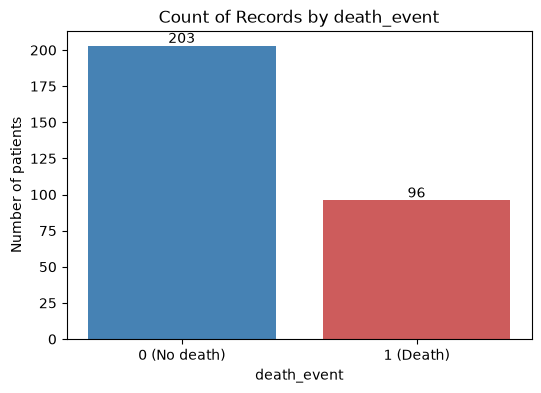

In [9]:
# 11. Charts
#
# Chart 1 – death_event bar chart

counts = df['death_event'].value_counts().sort_index()
plt.figure(figsize=(6, 4))
bars = plt.bar(['0 (No death)', '1 (Death)'], counts.values, color=['steelblue', 'indianred'])
for b in bars:
    plt.text(b.get_x() + b.get_width()/2, b.get_height() + 2, int(b.get_height()), ha='center')
plt.title('Count of Records by death_event')
plt.xlabel('death_event')
plt.ylabel('Number of patients')
plt.savefig('../images/death_event_bar.png', dpi=150, bbox_inches='tight')
plt.show()

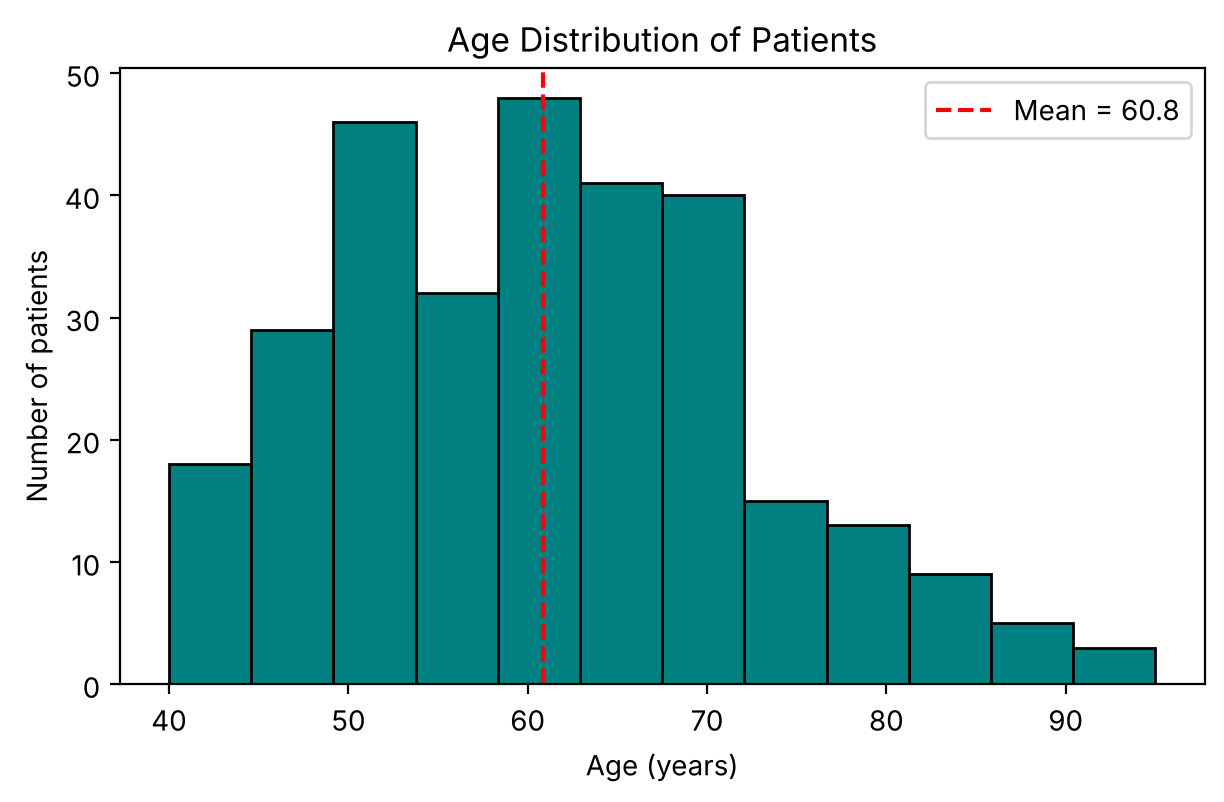

In [22]:
# Chart 2 – Age histogram

plt.figure(figsize=(7, 4))
plt.hist(df['age'], bins=12, color='teal', edgecolor='black')
plt.axvline(df['age'].mean(), color='red', linestyle='--', label=f"Mean = {df['age'].mean():.1f}")
plt.title('Age Distribution of Patients')
plt.xlabel('Age (years)')
plt.ylabel('Number of patients')
plt.legend()
plt.savefig('../images/age_histogram.png', dpi=150, bbox_inches='tight')
plt.show()

In [ ]:
# 12. Observations
#
# 1. Dataset quality and age: The dataset has 299 records and 13 columns with no missing
#    values and no duplicate rows. Patient ages range from 40 to 95 with a mean of about
#    60.8 and a median of 60, so the age distribution is fairly balanced, with most
#    patients between 50 and 70 years old (the 60–69 group is the largest).
# 2. Death event counts: 203 patients (about 67.9%) have death_event = 0 and 96 patients
#    (about 32.1%) have death_event = 1, so the two groups are not equal in size – roughly
#    one in three records is a death event.
# 3. Group comparison: The group with death_event = 1 has a lower average
#    ejection_fraction (about 33.5 vs 40.3) and a higher average serum_creatinine (about
#    1.84 vs 1.18) than the group with death_event = 0. Serum_creatinine also has a very
#    large maximum (9.4) compared to its median (1.1), which suggests a few extreme
#    values. These are only descriptive differences in this dataset; they do not prove
#    cause and no clinical conclusion is drawn.
#
# Conclusion
# Using only NumPy and Pandas, the data was loaded, checked for quality, summarised,
# grouped and visualised with two simple charts. This is basic EDA only – no machine
# learning and no clinical recommendations.